# Taller U2 — Asignación de turnos con un algoritmo genético

Resolvemos un problema sencillo de asignación de turnos con **PyGAD** y analizamos cómo la representación, las penalizaciones y los parámetros determinan la búsqueda.

# 1. El problema

Un equipo de $P=7$ personas debe cubrir $T=14$ turnos (7 días × 2 turnos). Dos reglas:

1. **Cobertura por turno:** cada turno necesita $K=3$ personas distintas.
2. **Máximo global por persona:** nadie puede trabajar más de $M=6$ turnos en la semana.

Demanda $=14\times3=42$ y capacidad $=7\times6=42$: **no sobra ningún turno**, cada persona debe trabajar exactamente 6 turnos.

Una **solución** es la asignación de una persona a cada uno de los 42 cupos. Cada cupo admite 7 valores, por lo que existen:

$$
7^{42}\approx3.1\times10^{35}
$$

asignaciones posibles. Revisarlas todas no es razonable.

In [1]:
%pip -q install pygad

import matplotlib.pyplot as plt
import numpy as np
import pygad

P = 7  # personas
T = 14  # turnos
K = 3  # personas por turno
M = 6  # máximo de turnos por persona

NUM_GENES = T * K
SEED = 42

print("PyGAD:", pygad.__version__)
print("Genes por cromosoma:", NUM_GENES)

espacio = P**NUM_GENES
print(f"Asignaciones posibles: {espacio:.2e}")
print(f"Años evaluando 1e9 por segundo: {espacio / 1e9 / (3600 * 24 * 365):.2e}")

Note: you may need to restart the kernel to use updated packages.


PyGAD: 3.7.0
Genes por cromosoma: 42
Asignaciones posibles: 3.12e+35
Años evaluando 1e9 por segundo: 9.89e+18


# 2. Representación

Cromosoma de **enteros**: un gen por cada cupo de cada turno, cuyo valor es la persona asignada.

$$
X\in\{0,\ldots,6\}^{42}
\qquad\longleftrightarrow\qquad
(14,3)
$$

Cada gen puede tomar cualquier valor de $\{0,\ldots,6\}$ de forma independiente. Por eso cualquier cruce entre dos cromosomas produce otro vector de 42 enteros en ese rango, es decir, **otro cromosoma con el mismo formato**. En una permutación (Laboratorio 3) un cruce de un punto podía repetir u omitir elementos y producir hijos inválidos.

Las reglas no están garantizadas por la representación: las controla el fitness.

In [2]:
def decodificar(cromosoma):
    return np.asarray(cromosoma, dtype=int).reshape(T, K)

# 3. Fitness

Contamos las violaciones de cada regla:

- **Repeticiones:** en cada turno, $K-\text{personas distintas}$. Cada persona repetida cuenta una vez.
- **Excesos:** para cada persona, $\max(0,\ \text{turnos asignados}-M)$.

$$
fitness(X)=-(\text{repeticiones}+\text{excesos})
$$

Un horario válido tiene **cero violaciones**, es decir, $fitness=0$, que es el máximo posible.

In [3]:
def evaluar(X):
    X = np.asarray(X, dtype=int)

    # Cobertura: personas repetidas dentro de un turno
    repeticiones = 0
    for turno in range(T):
        repeticiones += K - len(np.unique(X[turno]))

    # Máximo global: turnos por encima de M
    excesos = 0
    for persona in range(P):
        turnos = np.count_nonzero(np.any(X == persona, axis=1))
        excesos += max(0, turnos - M)

    return {
        "violaciones": int(repeticiones + excesos),
        "repeticiones": int(repeticiones),
        "excesos": int(excesos),
    }


def mostrar_evaluacion(X):
    r = evaluar(X)

    print("Repeticiones:", r["repeticiones"])
    print("Excesos:", r["excesos"])
    print("Violaciones:", r["violaciones"])


def fitness_func(ga_instance, solution, solution_idx):
    return -evaluar(decodificar(solution))["violaciones"]

# 4. Referencia aleatoria

Generamos 1 000 asignaciones aleatorias para saber cuánto aporta el algoritmo genético.

Violaciones promedio: 8.319
Desviación estándar: 1.9802118573526417
Mínimo: 2
Asignaciones válidas (%): 0.0


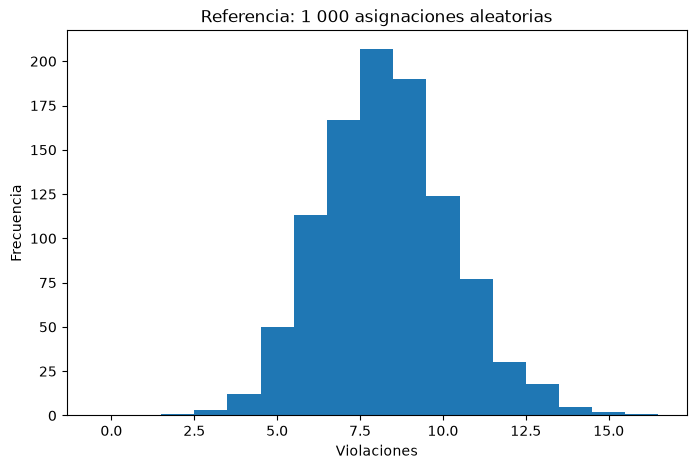

In [4]:
rng = np.random.default_rng(SEED)

aleatorias = rng.integers(0, P, size=(1000, NUM_GENES))
violaciones_aleatorias = np.array(
    [evaluar(decodificar(c))["violaciones"] for c in aleatorias]
)

print("Violaciones promedio:", violaciones_aleatorias.mean())
print("Desviación estándar:", violaciones_aleatorias.std())
print("Mínimo:", violaciones_aleatorias.min())
print("Asignaciones válidas (%):", 100 * np.mean(violaciones_aleatorias == 0))

plt.figure(figsize=(8, 5))
plt.hist(violaciones_aleatorias, bins=np.arange(violaciones_aleatorias.max() + 2) - 0.5)
plt.xlabel("Violaciones")
plt.ylabel("Frecuencia")
plt.title("Referencia: 1 000 asignaciones aleatorias")
plt.show()

# 5. Algoritmo genético

| Hiperparámetro | Valor |
|---|---|
| Tamaño de población | 100 |
| Padres por generación | 33 |
| Selección | torneo ($k=3$) |
| Cruce | un punto |
| Mutación | aleatoria, 5 % de genes (2 genes) |
| Elitismo | 2 individuos |
| Generaciones | máximo 300 (se detiene al llegar a 0 violaciones) |

El fitness es negativo, por eso usamos torneo: solo compara qué individuo es mejor.

In [5]:
historial = {"mejor": [], "promedio": []}


def on_generation(ga_instance):

    fitness = np.array(
        [
            fitness_func(ga_instance, ind, i)
            for i, ind in enumerate(ga_instance.population)
        ]
    )

    historial["mejor"].append(fitness.max())
    historial["promedio"].append(fitness.mean())

    gen = ga_instance.generations_completed

    if gen == 1 or gen % 10 == 0:
        print(
            f"Generación {gen:4d} | "
            f"mejor={fitness.max():3.0f} | "
            f"promedio={fitness.mean():6.2f}"
        )

    if fitness.max() == 0:
        return "stop"


ga = pygad.GA(
    num_generations=300,
    sol_per_pop=100,
    num_parents_mating=33,
    num_genes=NUM_GENES,
    fitness_func=fitness_func,
    gene_type=int,
    gene_space=list(range(P)),
    parent_selection_type="tournament",
    K_tournament=3,
    crossover_type="single_point",
    mutation_type="random",
    mutation_percent_genes=5,
    keep_elitism=2,
    on_generation=on_generation,
    random_seed=SEED,
    suppress_warnings=True,
)

ga.run()

print("Generaciones ejecutadas:", ga.generations_completed)

Generación    1 | mejor= -2 | promedio= -7.35


Generación   10 | mejor= -2 | promedio= -5.27


Generación   20 | mejor= -1 | promedio= -3.74


Generación   30 | mejor= -1 | promedio= -4.50


Generación   40 | mejor= -1 | promedio= -4.52
Generación   50 | mejor= -1 | promedio= -4.23


Generación   60 | mejor= -1 | promedio= -4.03
Generación   70 | mejor= -1 | promedio= -4.40


Generación   80 | mejor= -1 | promedio= -4.72
Generación   90 | mejor= -1 | promedio= -4.11
Generaciones ejecutadas: 91


# 6. Mejor horario encontrado

Tabla turnos × personas: un 1 indica que la persona trabaja ese turno.

In [6]:
best_solution, best_fitness, _ = ga.best_solution()
best_X = decodificar(best_solution)

tabla = np.zeros((T, P), dtype=int)
for turno in range(T):
    for persona in best_X[turno]:
        tabla[turno, persona] = 1

print("Turno     | " + " ".join(f"P{p}" for p in range(P)) + " | Total")
for turno in range(T):
    dia, jornada = turno // 2 + 1, ["mañana", "tarde"][turno % 2]
    fila = "  ".join(str(v) for v in tabla[turno])
    print(f"D{dia} {jornada:6s} | {fila}  | {tabla[turno].sum()}")
print("Total     | " + " ".join(f"{v:2d}" for v in tabla.sum(axis=0)))

print()
mostrar_evaluacion(best_X)
print("Fitness:", best_fitness)

Turno     | P0 P1 P2 P3 P4 P5 P6 | Total
D1 mañana | 1  1  0  0  0  0  1  | 3
D1 tarde  | 1  0  0  0  0  1  1  | 3
D2 mañana | 0  0  1  1  1  0  0  | 3
D2 tarde  | 0  0  1  1  0  1  0  | 3
D3 mañana | 0  0  1  0  1  0  1  | 3
D3 tarde  | 0  0  0  1  0  1  1  | 3
D4 mañana | 1  1  1  0  0  0  0  | 3
D4 tarde  | 0  0  0  1  1  1  0  | 3
D5 mañana | 1  0  1  0  1  0  0  | 3
D5 tarde  | 0  1  0  0  0  1  1  | 3
D6 mañana | 1  1  0  1  0  0  0  | 3
D6 tarde  | 0  1  0  1  1  0  0  | 3
D7 mañana | 1  0  0  0  1  1  0  | 3
D7 tarde  | 0  1  1  0  0  0  1  | 3
Total     |  6  6  6  6  6  6  6

Repeticiones: 0
Excesos: 0
Violaciones: 0
Fitness: 0


**Verificación manual:** cada fila suma 3 (cobertura con personas distintas) y cada columna suma 6 (nadie supera el máximo). El horario cumple las dos reglas.

# 7. Experimento: porcentaje de genes mutados

Variamos solamente `mutation_percent_genes` y mantenemos todo lo demás constante. Con 42 genes, PyGAD muta:

| % | Genes mutados |
|---|---|
| 5 | 2 |
| 15 | 6 |
| 30 | 12 |

Cada valor se ejecuta con 5 semillas.

In [7]:
def ejecutar_ga(mutation_percent=5, seed=42, generaciones=300):
    best_history = []
    mean_history = []

    def callback(ga_instance):
        fitness = np.array(
            [
                fitness_func(ga_instance, ind, i)
                for i, ind in enumerate(ga_instance.population)
            ]
        )

        best_history.append(fitness.max())
        mean_history.append(fitness.mean())

        if fitness.max() == 0:
            return "stop"

    ga = pygad.GA(
        num_generations=generaciones,
        sol_per_pop=100,
        num_parents_mating=33,
        num_genes=NUM_GENES,
        fitness_func=fitness_func,
        gene_type=int,
        gene_space=list(range(P)),
        parent_selection_type="tournament",
        K_tournament=3,
        crossover_type="single_point",
        mutation_type="random",
        mutation_percent_genes=mutation_percent,
        keep_elitism=2,
        on_generation=callback,
        random_seed=seed,
        suppress_warnings=True,
    )

    ga.run()

    return {
        "violaciones": -best_history[-1],
        "generaciones": len(best_history),
        "best": np.array(best_history),
        "mean": np.array(mean_history),
    }

In [8]:
mutaciones = [5, 15, 30]
semillas = [0, 1, 2, 3, 4]

resultados = {}

for mp in mutaciones:
    resultados[mp] = [ejecutar_ga(mutation_percent=mp, seed=s) for s in semillas]

for mp in mutaciones:
    runs = resultados[mp]
    exitos = [r for r in runs if r["violaciones"] == 0]
    fallos = [int(r["violaciones"]) for r in runs if r["violaciones"] > 0]
    gens = np.array([r["generaciones"] for r in exitos])

    print(f"Mutación {mp}%")
    print(f"  semillas con horario válido: {len(exitos)}/{len(runs)}")
    if len(exitos) > 0:
        print(
            f"  generación de éxito: {gens.mean():.1f} ± {gens.std():.1f}  {gens.tolist()}"
        )
    if len(fallos) > 0:
        print(f"  violaciones finales sin éxito: {fallos}")
    print()

Mutación 5%
  semillas con horario válido: 5/5
  generación de éxito: 55.8 ± 18.7  [36, 83, 40, 73, 47]

Mutación 15%
  semillas con horario válido: 1/5
  generación de éxito: 176.0 ± 0.0  [176]
  violaciones finales sin éxito: [1, 1, 1, 1]

Mutación 30%
  semillas con horario válido: 0/5
  violaciones finales sin éxito: [1, 1, 1, 1, 1]



# 8. Convergencia y diversidad

Mejor fitness y fitness promedio para una ejecución (semilla 0) de cada configuración.

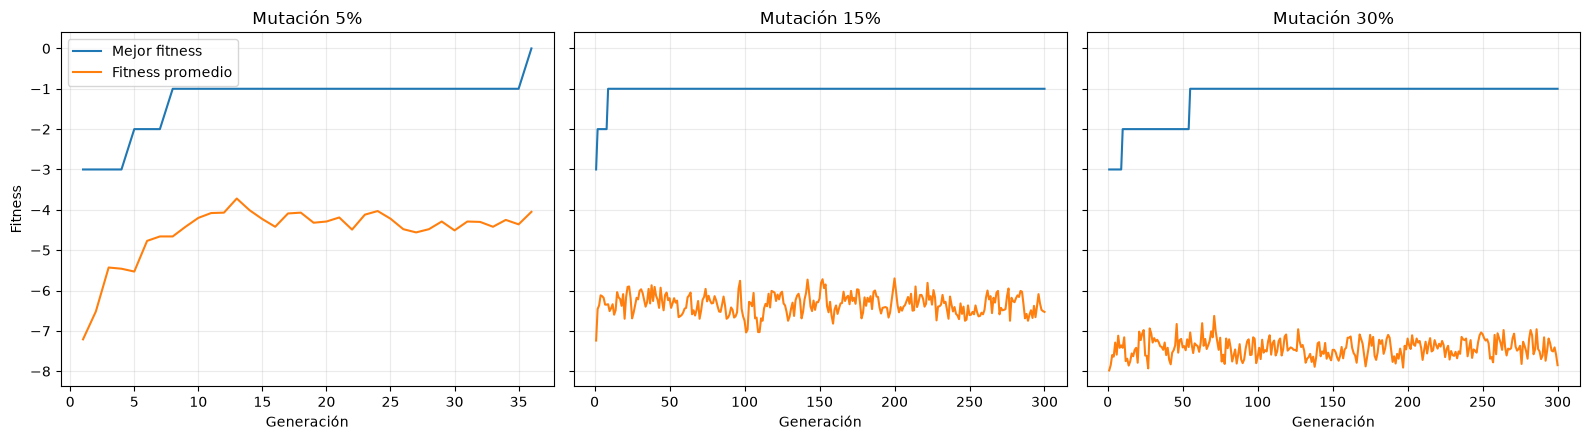

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, mp in zip(axes, mutaciones):
    r = resultados[mp][0]
    gens = np.arange(1, len(r["best"]) + 1)
    ax.plot(gens, r["best"], label="Mejor fitness")
    ax.plot(gens, r["mean"], label="Fitness promedio")
    ax.set_title(f"Mutación {mp}%")
    ax.set_xlabel("Generación")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Fitness")
axes[0].legend()
plt.tight_layout()
plt.show()

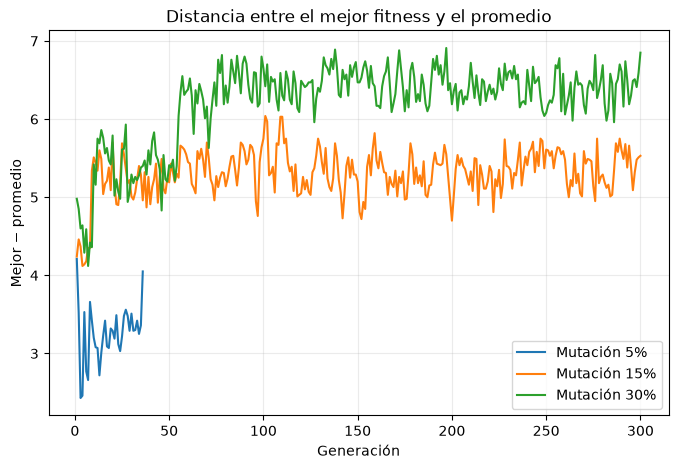

In [10]:
plt.figure(figsize=(8, 5))

for mp in mutaciones:
    r = resultados[mp][0]
    gens = np.arange(1, len(r["best"]) + 1)
    plt.plot(gens, r["best"] - r["mean"], label=f"Mutación {mp}%")

plt.xlabel("Generación")
plt.ylabel("Mejor − promedio")
plt.title("Distancia entre el mejor fitness y el promedio")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [11]:
for mp in mutaciones:
    runs = resultados[mp]

    # Generación de la última mejora en las semillas que no llegaron a 0
    ultima_mejora = [
        int(np.argmax(r["best"] == r["best"][-1])) + 1
        for r in runs
        if r["violaciones"] > 0
    ]

    # Fitness promedio de la población en las últimas 50 generaciones
    promedio_final = np.mean([r["mean"][-50:].mean() for r in runs])

    print(f"Mutación {mp}%")
    if len(ultima_mejora) > 0:
        print(f"  última mejora (semillas sin éxito): {ultima_mejora}")
    else:
        print("  última mejora: todas las semillas llegaron a 0 violaciones")
    print(f"  fitness promedio final: {promedio_final:.2f}")

Mutación 5%
  última mejora: todas las semillas llegaron a 0 violaciones
  fitness promedio final: -4.47
Mutación 15%
  última mejora (semillas sin éxito): [9, 26, 13, 89]
  fitness promedio final: -6.31
Mutación 30%
  última mejora (semillas sin éxito): [55, 27, 183, 145, 270]
  fitness promedio final: -7.43


### Análisis

- **¿Cuándo deja de mejorar?** Con 5 %, el mejor fitness llega a $0$ entre las generaciones 36 y 83. En las semillas que fallan, la última mejora (hasta $-1$) ocurre entre las generaciones 9 y 89 con 15 %, y entre la 27 y la 270 con 30 %; después no vuelve a mejorar hasta la generación 300.
- **Estancamiento sin horario válido:** 4 de 5 semillas con 15 % y todas con 30 % terminan con 1 violación.
- **Distancia mejor–promedio:** no se cierra en ninguna configuración, porque la mutación modifica a todos los hijos en cada generación, y crece con la mutación. El fitness promedio de las últimas generaciones es ≈ −4.5 (5 %), −6.3 (15 %) y −7.4 (30 %); este último está cerca del promedio aleatorio (−8.3).
- **Diversidad:** la población no pierde diversidad (no hay convergencia prematura), pero con mutación alta esa diversidad es ruido. Cada hijo hereda la estructura de sus padres y la pierde al mutar 6 o 12 genes. Pasar de 1 a 0 violaciones exige cambiar pocos genes de forma precisa, algo que una mutación grande destruye.

# 9. Conclusiones

1. **GA frente a aleatorio:** las 1 000 asignaciones aleatorias tienen 8.3 violaciones en promedio, ninguna es válida y la mejor tiene 2. El GA con 5 % de mutación encontró un horario válido en las 5 semillas, en 55.8 ± 18.7 generaciones.
2. **Efecto de la mutación:** al aumentarla bajó la tasa de éxito (5/5 → 1/5 → 0/5) y el fitness promedio se acercó al aleatorio. Una mutación baja aprovecha la estructura que construyen la selección y el cruce; una alta la destruye antes de que pueda aprovecharse.
3. **Ausencia de holgura (demanda igual a la capacidad):** cambiar la persona de un solo cupo en un horario válido siempre genera una violación, y los horarios válidos son una parte mínima de todos los posibles. Por eso ningún horario aleatorio fue válido, y las corridas con mutación alta quedaron a un error: el último paso exige un cambio exacto que una mutación grande no logra sin romper otra cosa.
4. **Nueva regla (no dos turnos seguidos):** se agrega un tercer término que cuente, para cada persona, los pares de turnos consecutivos $(t, t+1)$ que trabaja: $fitness=-(\text{repeticiones}+\text{excesos}+\text{consecutivos})$. Un horario válido seguiría siendo el de $fitness=0$.